# Phase 1 - Exploring the data (EDA)

**EDA = Exploratory Data Analysis.** Before building any model we *look* at the data to learn:
- Is the data clean, or are there weird rows we need to fix?
- What does "points in a game" look like as a distribution?
- Which things are actually related to points - and which ones would be **cheating** to use?
- How predictable is a single game at all?

Everything we learn here decides which features we build in Phase 2.

**How to use this notebook:** click a cell and press **Shift + Enter** to run it and move to the next one.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Let the notebook import from our src/ folder (the notebook lives one level down).
sys.path.append(str(Path.cwd().parent))
from src.config import RAW_DIR

# --- A consistent, clean chart style for the whole project ---
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.axisbelow": True, "axes.titlesize": 13, "figure.dpi": 110,
})
pd.set_option("display.width", 140)

## 1. Load all five seasons

We downloaded one file per season. `pd.concat` stacks them into one big table.

In [2]:
files = sorted(RAW_DIR.glob("player_logs_*.parquet"))
df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)

df["GAME_DATE"] = pd.to_datetime(df["GAME_DATE"])          # text -> real dates
df["HOME"] = df["MATCHUP"].str.contains("vs.").astype(int)  # "LAL vs. BOS" = home, "LAL @ BOS" = away
df["OPPONENT"] = df["MATCHUP"].str.split().str[-1]          # last word is the opponent

# Sort each player's games in time order - very important for "previous games" features later.
df = df.sort_values(["PLAYER_ID", "GAME_DATE"]).reset_index(drop=True)

print(f"{len(df):,} player-games, {df['PLAYER_ID'].nunique():,} players, {df['GAME_ID'].nunique():,} games")
df[["SEASON", "PLAYER_NAME", "GAME_DATE", "MATCHUP", "MIN", "FGA", "FG3A", "FTA", "PTS"]].head()

131,291 player-games, 1,029 players, 6,150 games


,SEASON,PLAYER_NAME,GAME_DATE,MATCHUP,MIN,FGA,FG3A,FTA,PTS
0,2021-22,Joe Johnson,2021-12-22,BOS vs. CLE,2,1,0,0,2
1,2021-22,LeBron James,2021-10-19,LAL vs. GSW,37,23,11,6,34
2,2021-22,LeBron James,2021-10-22,LAL vs. PHX,37,18,9,4,25
3,2021-22,LeBron James,2021-10-24,LAL vs. MEM,40,19,9,2,19
4,2021-22,LeBron James,2021-10-29,LAL vs. CLE,38,22,10,5,26


## 2. Data quality check

Real data is messy. Let's look for rows that don't make sense.

In [3]:
print("Rows where the player was listed but played 0 minutes:", (df["MIN"] == 0).sum())
print("Rows with more than 48 minutes (overtime games):     ", (df["MIN"] > 48).sum())
print("Missing values in key columns:", df[["MIN", "PTS", "FGA"]].isna().sum().sum())
print()
print("Highest-scoring games in the data (sanity check - are these real?):")
df.nlargest(5, "PTS")[["PLAYER_NAME", "GAME_DATE", "MATCHUP", "MIN", "FGA", "FTA", "PTS"]]

Rows where the player was listed but played 0 minutes: 461
Rows with more than 48 minutes (overtime games):      57
Missing values in key columns: 0

Highest-scoring games in the data (sanity check - are these real?):


,PLAYER_NAME,GAME_DATE,MATCHUP,MIN,FGA,FTA,PTS
44886,Bam Adebayo,2026-03-10,MIA vs. WAS,42,43,43,83
59928,Luka Dončić,2024-01-26,DAL @ ATL,45,33,16,73
13319,Damian Lillard,2023-02-26,POR vs. HOU,39,38,14,71
42771,Donovan Mitchell,2023-01-02,CLE vs. CHI,50,34,25,71
24757,Joel Embiid,2024-01-22,PHI vs. SAS,37,41,23,70


**Decision:** we drop the 0-minute rows. A player who never got off the bench didn't really "play" -
and in a real prediction we'd only predict for players expected to play.

In [4]:
df = df[df["MIN"] > 0].copy()
print(f"{len(df):,} rows after cleaning")

130,830 rows after cleaning


## 3. What does "points in a game" look like?

This is our **target** - the thing we're trying to predict.

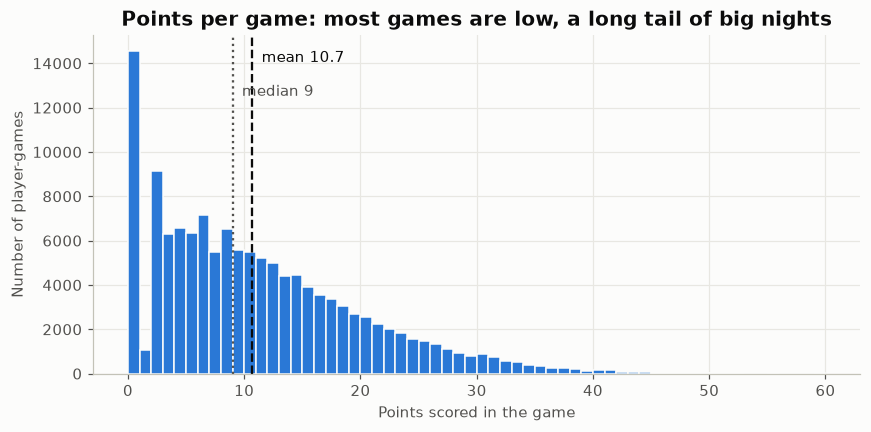

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df["PTS"], bins=range(0, 61), color=BLUE, edgecolor="#fcfcfb", linewidth=1)
mean, median = df["PTS"].mean(), df["PTS"].median()
ax.axvline(mean, color=INK, linestyle="--", linewidth=1.5)
ax.axvline(median, color=INK_2, linestyle=":", linewidth=1.5)
ax.text(mean + 0.8, ax.get_ylim()[1] * 0.92, f"mean {mean:.1f}", color=INK)
ax.text(median + 0.8, ax.get_ylim()[1] * 0.82, f"median {median:.0f}", color=INK_2)
ax.set(title="Points per game: most games are low, a long tail of big nights",
       xlabel="Points scored in the game", ylabel="Number of player-games")
plt.show()

**What this tells us:** the shape is **right-skewed** - piled up near 0-10 with a long tail to the right.
It is *not* a symmetric bell curve. Keep this in mind for Phase 6 (distribution models): a plain
Normal distribution will be a so-so fit.

## 4. Minutes vs points - the single biggest driver

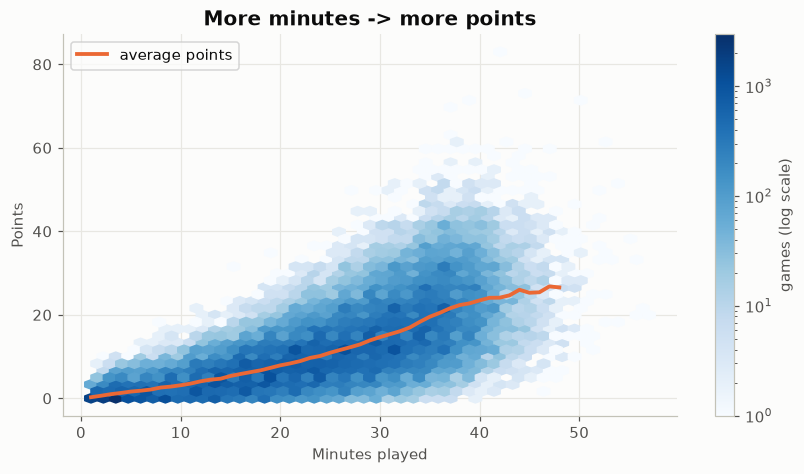

Correlation between minutes and points: 0.74  (1.0 = perfect line, 0 = no relationship)


In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
hb = ax.hexbin(df["MIN"], df["PTS"], gridsize=45, cmap="Blues", mincnt=1, bins="log")
avg_by_min = df.groupby(df["MIN"].clip(upper=48))["PTS"].mean()
ax.plot(avg_by_min.index, avg_by_min.values, color=ORANGE, linewidth=2.5, label="average points")
ax.set(title="More minutes -> more points", xlabel="Minutes played", ylabel="Points")
ax.legend(loc="upper left")
fig.colorbar(hb, ax=ax, label="games (log scale)")
plt.show()
print(f"Correlation between minutes and points: {df['MIN'].corr(df['PTS']):.2f}  (1.0 = perfect line, 0 = no relationship)")

**What this tells us:** points rise almost in a straight line with minutes. But notice the *spread* at
each minute value - a player with 35 minutes can score 5 or 40. Minutes explain **a lot**, not everything.

## 5. The cheating trap (data leakage) - the most important chart in this notebook

Stats from **the same game** (like that game's shot attempts) are almost perfectly related to points.
But you can't know them before tip-off! What we *can* know is a player's **average over his previous 10 games**.

Below we compare both. `shift(1)` means "move everything down one game", so a row only sees *earlier* games.

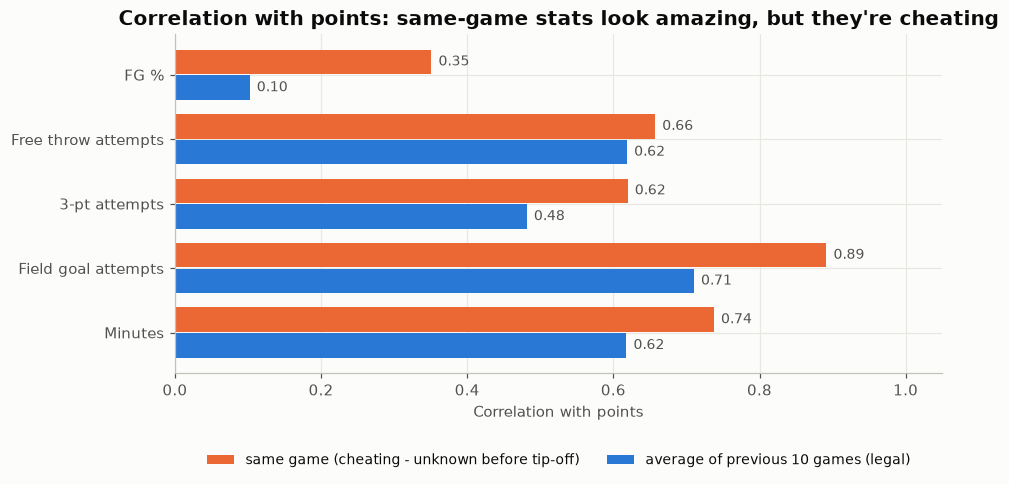

In [7]:
stats = ["MIN", "FGA", "FG3A", "FTA", "FG_PCT"]
by_player = df.groupby("PLAYER_ID")

for s in stats:
    # Average of the previous 10 games (NOT including this one) - this is legal to use.
    df[f"{s}_last10"] = by_player[s].transform(lambda x: x.shift(1).rolling(10, min_periods=3).mean())
df["PTS_last10"] = by_player["PTS"].transform(lambda x: x.shift(1).rolling(10, min_periods=3).mean())

same_game = [df[s].corr(df["PTS"]) for s in stats]
pre_game = [df[f"{s}_last10"].corr(df["PTS"]) for s in stats]

y = np.arange(len(stats))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(y + 0.2, same_game, height=0.38, color=ORANGE, label="same game (cheating - unknown before tip-off)")
ax.barh(y - 0.2, pre_game, height=0.38, color=BLUE, label="average of previous 10 games (legal)")
for i in range(len(stats)):
    ax.text(same_game[i] + 0.01, i + 0.2, f"{same_game[i]:.2f}", va="center", color=INK_2, fontsize=9)
    ax.text(pre_game[i] + 0.01, i - 0.2, f"{pre_game[i]:.2f}", va="center", color=INK_2, fontsize=9)
ax.set_yticks(y, ["Minutes", "Field goal attempts", "3-pt attempts", "Free throw attempts", "FG %"])
ax.set(title="Correlation with points: same-game stats look amazing, but they're cheating",
       xlabel="Correlation with points", xlim=(0, 1.05))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=9, frameon=False)
plt.show()

**What this tells us:** if we fed the model the same-game stats, it would look like a genius - and be
useless in real life. Every feature we build in Phase 2 will be the **legal (blue)** kind.

Also notice same-game FG% is useful (a hot shooting night = more points) but the *previous-10-game* FG%
barely helps. Shooting luck mostly doesn't carry over from game to game; **volume (shots, minutes) does.**

## 6. How much does one player bounce around game to game?

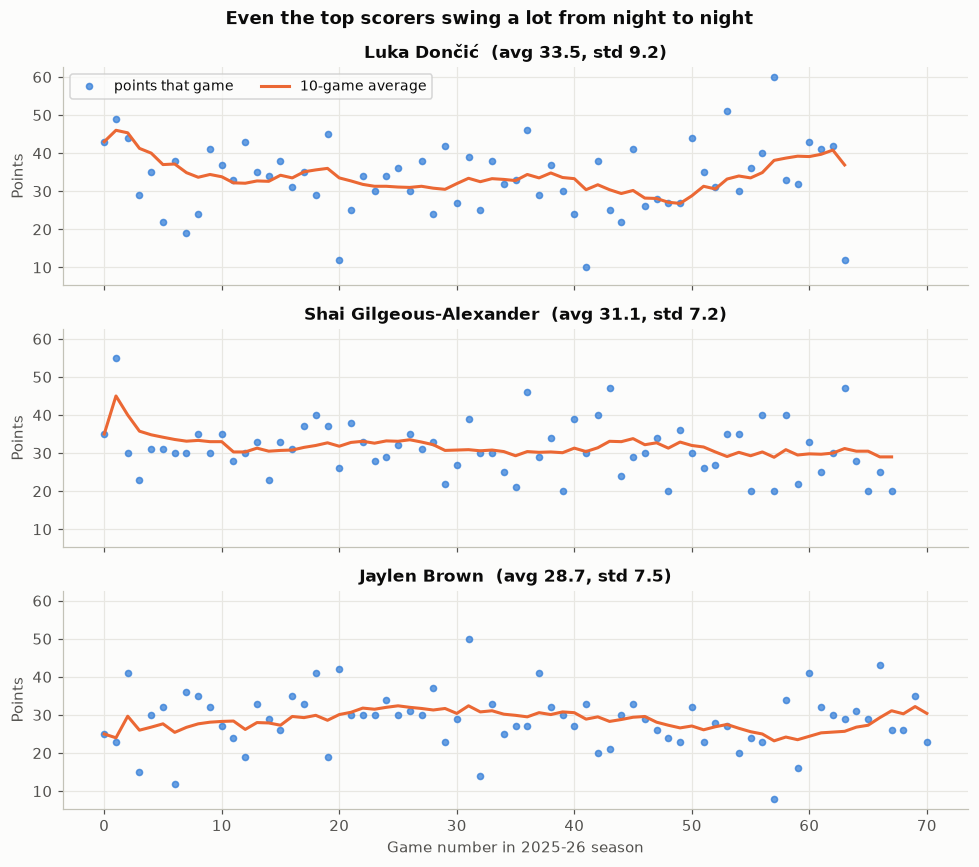

In [8]:
latest = df[df["SEASON"] == df["SEASON"].max()]
top3 = latest.groupby("PLAYER_NAME")["PTS"].sum().nlargest(3).index

fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True, sharey=True)
for ax, name in zip(axes, top3):
    p = latest[latest["PLAYER_NAME"] == name]
    ax.plot(range(len(p)), p["PTS"], "o", color=BLUE, markersize=4, alpha=0.7, label="points that game")
    ax.plot(range(len(p)), p["PTS"].rolling(10, min_periods=1).mean(), color=ORANGE, linewidth=2, label="10-game average")
    ax.set_title(f"{name}  (avg {p['PTS'].mean():.1f}, std {p['PTS'].std():.1f})", fontsize=11)
    ax.set_ylabel("Points")
axes[0].legend(loc="upper left", fontsize=9, ncol=2)
axes[-1].set_xlabel(f"Game number in {df['SEASON'].max()} season")
fig.suptitle("Even the top scorers swing a lot from night to night", fontweight="bold")
plt.tight_layout()
plt.show()

**What this tells us:** even for the most consistent stars, single games swing roughly +/-7 points around
their average. That randomness is a **floor on how accurate any model can be** - no model will get
every game right, and that's normal.

Next: does the swing size depend on how good the scorer is?

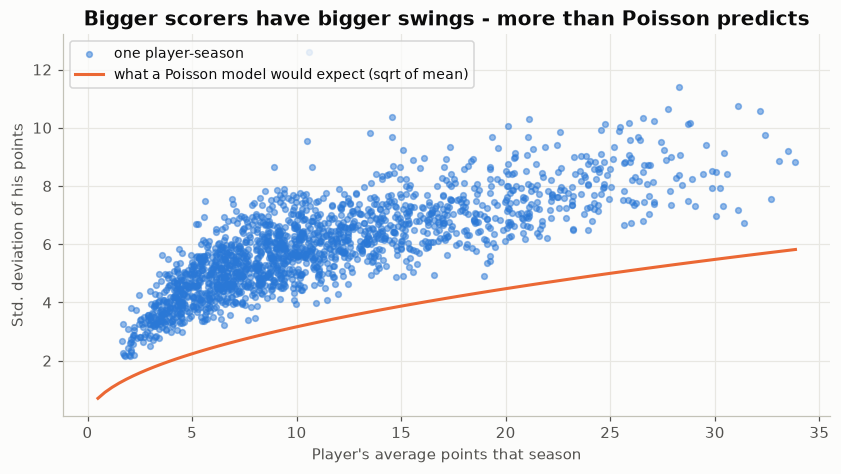

In [9]:
ps = df.groupby(["PLAYER_ID", "SEASON"])["PTS"].agg(["mean", "std", "count"])
ps = ps[ps["count"] >= 40]  # only player-seasons with enough games to measure

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(ps["mean"], ps["std"], s=14, color=BLUE, alpha=0.5, label="one player-season")
xs = np.linspace(0.5, ps["mean"].max(), 100)
ax.plot(xs, np.sqrt(xs), color=ORANGE, linewidth=2, label="what a Poisson model would expect (sqrt of mean)")
ax.set(title="Bigger scorers have bigger swings - more than Poisson predicts",
       xlabel="Player's average points that season", ylabel="Std. deviation of his points")
ax.legend(loc="upper left", fontsize=9)
plt.show()

**What this tells us:** the spread grows with the average, and it's bigger than the simplest count model
(Poisson) expects. This is called **overdispersion**, and it's why in Phase 6 we'll try a
**Negative Binomial** distribution, which allows extra spread.

## 7. Sneak peek: how well do simple guesses do?

Before any machine learning, how far off are simple guesses? We measure with **MAE (Mean Absolute Error)**:
the average number of points the guess misses by. Lower is better.

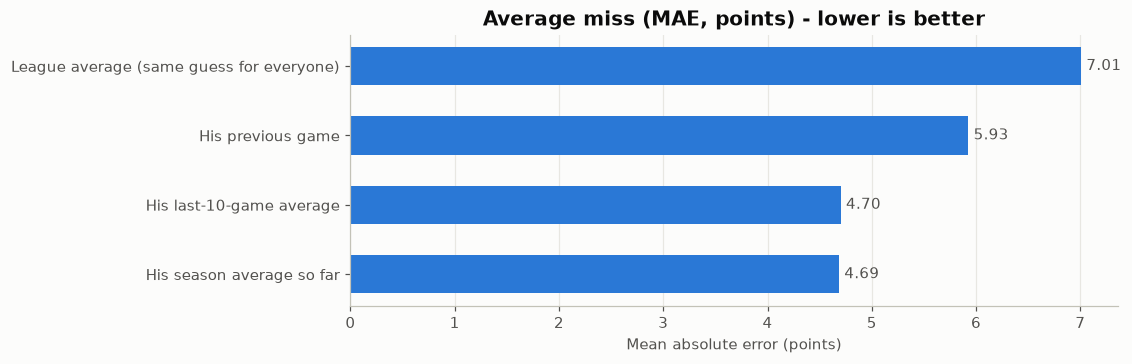

In [10]:
df["PTS_prev_game"] = by_player["PTS"].shift(1)
df["PTS_season_avg"] = df.groupby(["PLAYER_ID", "SEASON"])["PTS"].transform(lambda x: x.shift(1).expanding().mean())

# Only score rows where every guess exists, so the comparison is fair.
eval_rows = df.dropna(subset=["PTS_prev_game", "PTS_last10", "PTS_season_avg"])
league_avg = df["PTS"].mean()

guesses = {
    "League average (same guess for everyone)": np.full(len(eval_rows), league_avg),
    "His previous game": eval_rows["PTS_prev_game"],
    "His last-10-game average": eval_rows["PTS_last10"],
    "His season average so far": eval_rows["PTS_season_avg"],
}
mae = {name: np.mean(np.abs(eval_rows["PTS"] - g)) for name, g in guesses.items()}

fig, ax = plt.subplots(figsize=(9, 3.2))
names = list(mae)[::-1]
ax.barh(names, [mae[n] for n in names], color=BLUE, height=0.55)
for i, n in enumerate(names):
    ax.text(mae[n] + 0.05, i, f"{mae[n]:.2f}", va="center", color=INK_2)
ax.set(title="Average miss (MAE, points) - lower is better", xlabel="Mean absolute error (points)")
ax.grid(axis="y", visible=False)
plt.show()

**What this tells us:** just using a player's own recent average cuts the error a lot compared to a
blind guess. These simple guesses become our official **baselines** in Phase 4 - every fancy model
later has to beat them, or it isn't worth it.

## 8. Does the opponent's defense matter?

We compute each team's **defensive rating** = points allowed per 100 possessions (lower = better defense)
from the team game logs. Possessions are estimated with the standard formula:
`FGA + 0.44 * FTA - OREB + TOV`.

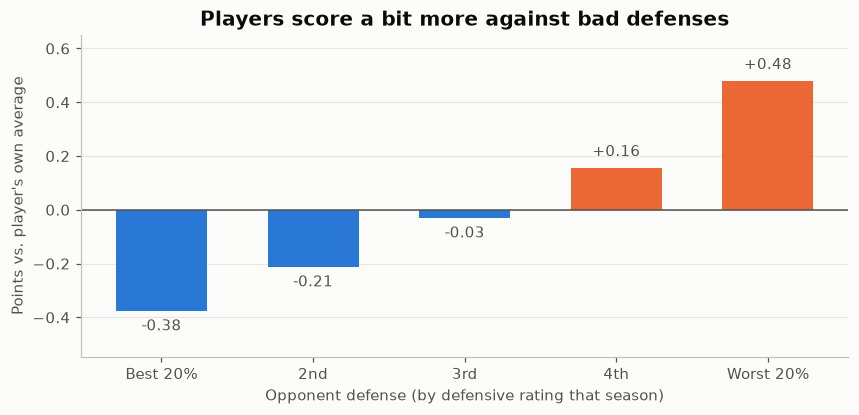

In [11]:
team = pd.concat([pd.read_parquet(f) for f in sorted(RAW_DIR.glob("team_logs_*.parquet"))], ignore_index=True)
team["POSS"] = team["FGA"] + 0.44 * team["FTA"] - team["OREB"] + team["TOV"]

# Pair each team's row with its opponent's row from the same game.
opp = team[["GAME_ID", "TEAM_ID", "PTS", "POSS"]].rename(
    columns={"TEAM_ID": "OPP_ID", "PTS": "OPP_PTS", "POSS": "OPP_POSS"})
games = team.merge(opp, on="GAME_ID")
games = games[games["TEAM_ID"] != games["OPP_ID"]]

# Season-level defensive rating per team (points allowed per 100 possessions).
d = games.groupby(["SEASON", "TEAM_ABBREVIATION"]).agg(pts_allowed=("OPP_PTS", "sum"), poss=("OPP_POSS", "sum"))
d["DEF_RTG"] = 100 * d["pts_allowed"] / d["poss"]
def_rtg = d["DEF_RTG"].reset_index().rename(columns={"TEAM_ABBREVIATION": "OPPONENT", "DEF_RTG": "OPP_DEF_RTG"})

df = df.merge(def_rtg, on=["SEASON", "OPPONENT"], how="left")

# "Points above his own season average" - removes the fact that stars score more than bench players.
df["PTS_vs_avg"] = df["PTS"] - df.groupby(["PLAYER_ID", "SEASON"])["PTS"].transform("mean")

df["def_group"] = pd.qcut(df["OPP_DEF_RTG"], 5, labels=["Best 20%", "2nd", "3rd", "4th", "Worst 20%"])
effect = df.groupby("def_group", observed=True)["PTS_vs_avg"].mean()

fig, ax = plt.subplots(figsize=(9, 3.8))
colors = [BLUE if v < 0 else ORANGE for v in effect.values]
ax.bar(effect.index.astype(str), effect.values, color=colors, width=0.6)
ax.axhline(0, color=INK_2, linewidth=1)
for i, v in enumerate(effect.values):
    ax.text(i, v + (0.03 if v >= 0 else -0.03), f"{v:+.2f}", ha="center", va="bottom" if v >= 0 else "top", color=INK_2)
ax.margins(y=0.2)
ax.set(title="Players score a bit more against bad defenses",
       xlabel="Opponent defense (by defensive rating that season)", ylabel="Points vs. player's own average")
ax.grid(axis="x", visible=False)
plt.show()

**What this tells us:** the opponent matters, but the effect is **small** (fractions of a point on average)
compared to minutes. Small but real effects are exactly what models like regression and trees can add on top
of a player's average.

*(Note: here we used each opponent's full-season rating, which includes future games - fine for exploring,
but in Phase 2 we'll compute it using only games played **before** each date.)*

## 9. Home vs away, and rest days

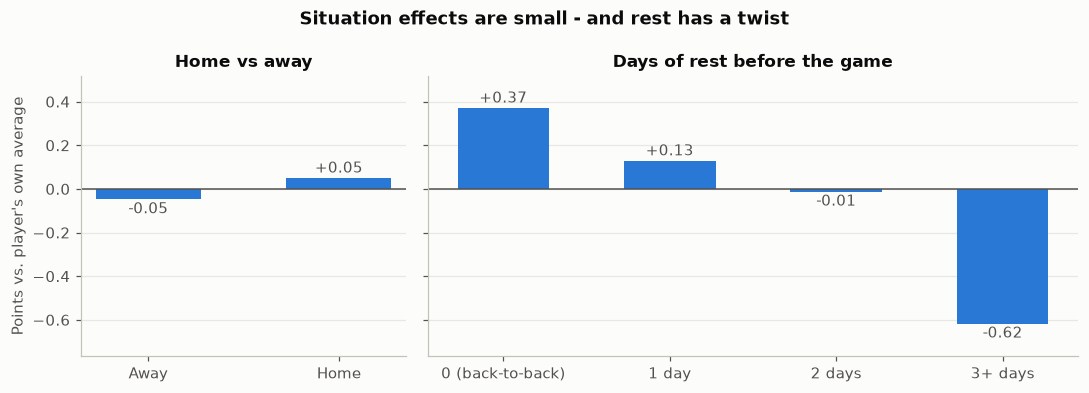

In [12]:
df["REST_DAYS"] = df.groupby(["PLAYER_ID", "SEASON"])["GAME_DATE"].diff().dt.days - 1
df["rest_group"] = pd.cut(df["REST_DAYS"], [-1, 0, 1, 2, 100], labels=["0 (back-to-back)", "1 day", "2 days", "3+ days"])

home = df.groupby("HOME")["PTS_vs_avg"].mean().rename({0: "Away", 1: "Home"})
rest = df.groupby("rest_group", observed=True)["PTS_vs_avg"].mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True, gridspec_kw={"width_ratios": [2, 4]})
for ax, series, title in [(axes[0], home, "Home vs away"), (axes[1], rest, "Days of rest before the game")]:
    ax.bar(series.index.astype(str), series.values, color=BLUE, width=0.55)
    ax.axhline(0, color=INK_2, linewidth=1)
    for i, v in enumerate(series.values):
        ax.text(i, v + (0.01 if v >= 0 else -0.01), f"{v:+.2f}", ha="center", va="bottom" if v >= 0 else "top", color=INK_2)
    ax.set_title(title, fontsize=11)
    ax.margins(y=0.15)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Points vs. player's own average")
fig.suptitle("Situation effects are small - and rest has a twist", fontweight="bold")
plt.tight_layout()
plt.show()

**What this tells us:** home court is worth almost nothing for an individual's points (+/-0.05).

The rest result looks **backwards** - more rest = *fewer* points? This is a classic trap called **confounding**:
a player with 3+ days off is often coming back from an **injury** (and plays limited minutes), while
players who suit up on a back-to-back are the healthy, important ones. The rest days aren't *causing* the drop;
something hidden is behind both. Models can still use this pattern, but we should be careful how we
interpret it. A cleaner feature later will be "games missed recently".

## 10. Summary - what we learned

| # | Finding | What it means for the project |
|---|---|---|
| 1 | 130,830 usable player-games after dropping 461 zero-minute rows. The 83-point game (Bam Adebayo, Mar 2026) is in the official data, not an error. | Data is clean enough to build on. |
| 2 | Points are **right-skewed** (mean 10.7, median 9). | A Normal curve is a rough fit; try Negative Binomial in Phase 6. |
| 3 | **Minutes** are the biggest driver (correlation 0.74). | We need a good *projected minutes* feature - it may even deserve its own model. |
| 4 | Same-game stats are **leakage**. Legal recent averages are weaker but real. Shot *volume* carries over between games; shooting *percentage* barely does (0.10). | Build features from previous games only; lean on volume and usage, not hot/cold shooting. |
| 5 | Even stars swing ~7-9 points game to game, and spread grows faster than Poisson predicts. | There's a noise floor no model beats; distribution models must allow extra spread. |
| 6 | Simple averages miss by **~4.7 points** vs **7.0** for a blind guess. | **4.7 is the number to beat.** |
| 7 | Opponent defense: about +/-0.4 points. Home: ~0. Rest: confounded by injuries. | Small effects - useful as extra features, but they won't change predictions much. |

### Features we'll build in Phase 2
- Recent form: points, minutes, FGA, 3PA, FTA averaged over last 3 / 5 / 10 games + season-to-date
- Opponent defensive rating and pace - **computed only from games before that date**
- Home/away, rest days, games played recently